# Common Test I - Multi-class lens classification

Classes: no substructure, subhalo substructure, vortex substructure.
Metrics: ROC curve and AUC on the validation data (90:10 split).

## 0. Setup

**Run on Colab:** Runtime -> Change runtime type -> **T4 GPU**, then Runtime -> Run all (about 25-30 minutes on a T4).
Locally the notebook only runs as a tiny CPU smoke test (`DEEPLENSE_SMOKE=1`).

- Imports, random seed, device (GPU check)

In [2]:
import json
import os
import random
import sys
import time
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import auc, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

IN_COLAB = "google.colab" in sys.modules
SMOKE = os.environ.get("DEEPLENSE_SMOKE") == "1"  # tiny CPU check of the code, not a real run

# fix the seeds so a rerun gives the same numbers
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device, "| Colab:", IN_COLAB, "| smoke:", SMOKE)
if device.type == "cpu" and not SMOKE:
    print("WARNING: no GPU found. On Colab pick Runtime -> Change runtime type -> T4 GPU. "
          "On CPU the full run would take hours.")

torch 2.14.1+cu130 | device: cuda | Colab: True | smoke: False


## 1. Get the data

- Download `dataset.zip` (link in the test document) and unzip it into `data/`
- Questions: what is the folder layout? what is the file format (.npy / .png)?

In [3]:
# gdown downloads public Google Drive files by id
try:
    import gdown
except ImportError:  # Colab has it already; this is for a fresh local environment
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "gdown"])
    import gdown

DATA_DIR = Path("/content/data") if IN_COLAB else Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = DATA_DIR / "dataset.zip"
RAW_DIR = DATA_DIR / "raw"

# the id comes from the "dataset.zip" link in the test document
FILE_ID = "1ZEyNMEO43u3qhJAwJeBZxFBEYc_pVYZQ"

# Google Drive downloads sometimes drop the connection, so try a few times
for attempt in range(1, 4):
    if ZIP_PATH.exists():
        break
    try:
        gdown.download(id=FILE_ID, output=str(ZIP_PATH), quiet=False)
    except Exception as exc:
        print(f"download attempt {attempt} failed: {exc}")
if not ZIP_PATH.exists():
    raise RuntimeError("Could not download dataset.zip, download it by hand from the test document.")

if not RAW_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)
print("ready:", RAW_DIR)

ready: /content/data/raw


In [4]:
# the zip also contains a __MACOSX folder with junk, so only look inside dataset/
ROOT = RAW_DIR / "dataset"
CLASSES = ["no", "sphere", "vort"]

for split in ("train", "val"):
    for name in CLASSES:
        n = len(list((ROOT / split / name).glob("*.npy")))
        print(f"{split:5s} {name:7s} {n} files")

train no      10000 files
train sphere  10000 files
train vort    10000 files
val   no      2500 files
val   sphere  2500 files
val   vort    2500 files


## 2. Look at the data first

- How many images per class? Are the classes balanced?
- Image shape and value range (the test says min-max normalized)
- Plot a few samples of each class. Can you see the difference by eye?

In [5]:
# shape and value range of the first image of each class
for name in CLASSES:
    img = np.load(sorted((ROOT / "train" / name).glob("*.npy"))[0])
    print(f"{name:7s} shape={img.shape} dtype={img.dtype} min={img.min():.3f} max={img.max():.3f}")

no      shape=(1, 150, 150) dtype=float64 min=0.000 max=1.000
sphere  shape=(1, 150, 150) dtype=float64 min=0.000 max=1.000
vort    shape=(1, 150, 150) dtype=float64 min=0.000 max=1.000


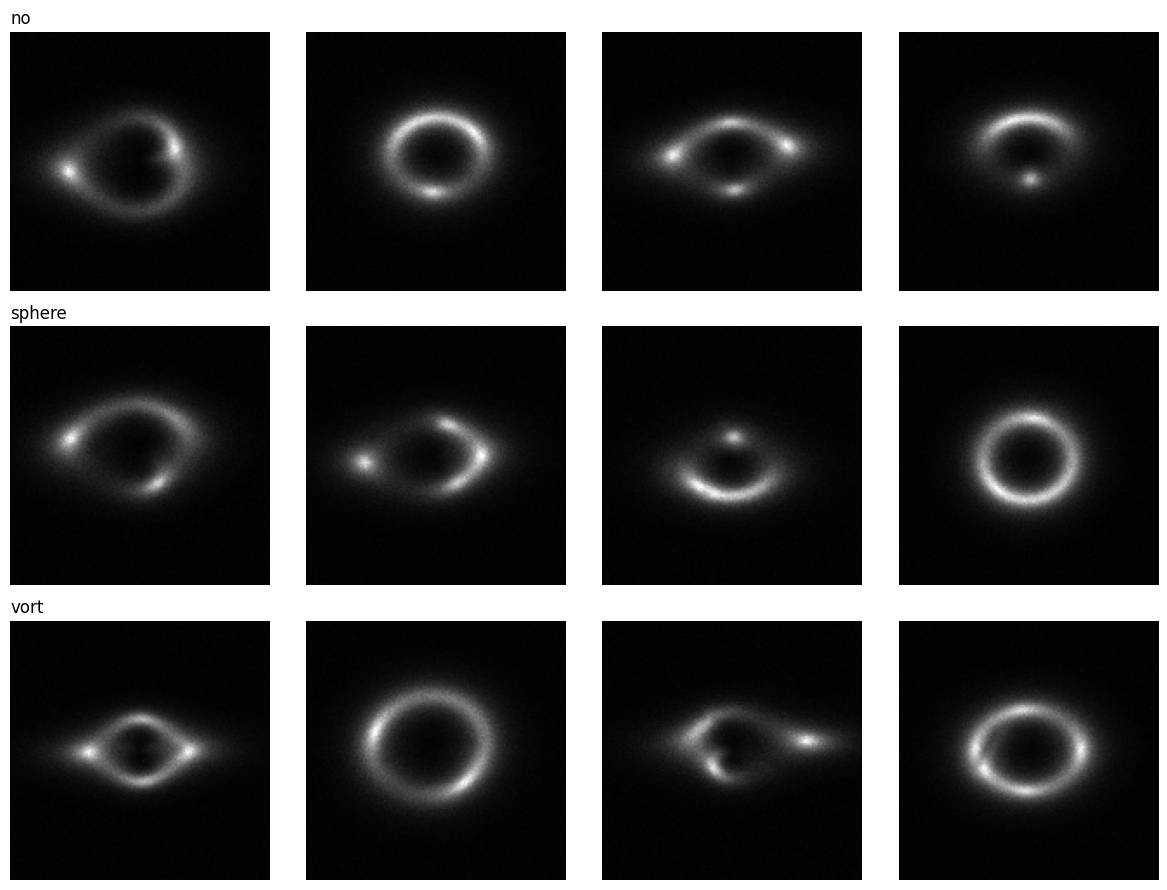

In [6]:
# 4 random training images per class
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 9))
for row, name in enumerate(CLASSES):
    files = sorted((ROOT / "train" / name).glob("*.npy"))
    for col, f in enumerate(random.sample(files, 4)):
        axes[row, col].imshow(np.squeeze(np.load(f)), cmap="gray")
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(name, loc="left")
plt.tight_layout()
plt.show()

## 3. Train / validation split (90:10)

What the data looks like (found by inspecting dataset.zip):
- Three classes: no, sphere, vort. Each image is 1x150x150, float64, min-max normalised to 0-1.
- It already ships with train/ (10,000 per class) and val/ (2,500 per class). That is an 80:20 split, but the test asks for 90:10.
- Decision to make and justify: pool all 12,500 images per class and re-split 90:10 (stratified), or keep the given split. Write the reason here.

Also think about: why stratified? why must validation images never be used for training?

In [7]:
# pool the shipped train and val folders, then split 90:10 ourselves
paths, labels = [], []
for label, name in enumerate(CLASSES):
    for split in ("train", "val"):
        for f in sorted((ROOT / split / name).glob("*.npy")):
            paths.append(f)
            labels.append(label)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    paths, labels, test_size=0.1, stratify=labels, random_state=SEED
)
print("train:", len(train_paths), Counter(train_labels))
print("val:  ", len(val_paths), Counter(val_labels))

train: 33750 Counter({2: 11250, 1: 11250, 0: 11250})
val:   3750 Counter({2: 1250, 0: 1250, 1: 1250})


## 4. Dataset and DataLoader

- A `torch.utils.data.Dataset` that returns (image tensor, label)
- Batch size and why

In [8]:
class LensDataset(Dataset):
    """Loads every image into memory once as float32, so epochs don't re-read the disk."""

    def __init__(self, paths, labels):
        x = np.empty((len(paths), 1, 150, 150), dtype=np.float32)
        for i, p in enumerate(paths):
            x[i] = np.load(p)
        self.x = torch.from_numpy(x)
        self.y = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


train_ds = LensDataset(train_paths, train_labels)
val_ds = LensDataset(val_paths, val_labels)

BATCH_SIZE = 64
PIN = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=PIN)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, pin_memory=PIN)
print(train_ds.x.shape, val_ds.x.shape)

torch.Size([33750, 1, 150, 150]) torch.Size([3750, 1, 150, 150])


## 5. Baseline model (small CNN)

- Write the simplest model that could work, train it, record the numbers
- This is the number every later idea has to beat

In [9]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class SmallCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 16), conv_block(16, 32), conv_block(32, 64), conv_block(64, 128)
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))


model = SmallCNN().to(device)
print(sum(p.numel() for p in model.parameters()), "parameters")

98019 parameters


In [10]:
@torch.no_grad()
def predict(model, loader):
    """Returns softmax probabilities and true labels for a whole loader."""
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        probs.append(torch.softmax(model(x.to(device)), dim=1).cpu())
        ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


def augment(x):
    """Random mirror and 90-degree turn of a whole batch (new random choice for every batch).

    Assumption: a lens image keeps its class when mirrored or rotated. For the vortex class this holds by
    construction, DeepLenseSim draws a random angle for it (`ang = 2 * pi * random`).
    """
    if torch.rand(1).item() < 0.5:
        x = x.flip(-1)
    if torch.rand(1).item() < 0.5:
        x = x.flip(-2)
    return torch.rot90(x, int(torch.randint(0, 4, (1,)).item()), dims=(-2, -1))


def fit(model, epochs, lr=1e-3, opt="adam", weight_decay=0.0, cosine=False, use_augment=False, tag=""):
    """Train `model` for `epochs`. Reports the LAST epoch (no picking of the best epoch on the validation set)."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    if opt == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs) if cosine else None

    started = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if use_augment:
                x = augment(x)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(y)
        if scheduler:
            scheduler.step()

        probs, ys = predict(model, val_loader)
        val_acc = float((probs.argmax(1) == ys).mean())
        val_auc = float(roc_auc_score(ys, probs, multi_class="ovr"))
        print(f"{tag}epoch {epoch:2d}  train loss {running / len(train_ds):.4f}  val acc {val_acc:.4f}  val AUC {val_auc:.4f}")
    return {"acc": val_acc, "auc": val_auc, "seconds": round(time.time() - started)}


EPOCHS = 2 if SMOKE else 15   # same for the baseline and every experiment, so the numbers are comparable
baseline_result = fit(model, EPOCHS, tag="baseline ")

baseline epoch  1  train loss 1.1005  val acc 0.3333  val AUC 0.5206
baseline epoch  2  train loss 1.0987  val acc 0.3333  val AUC 0.5115
baseline epoch  3  train loss 1.0717  val acc 0.4216  val AUC 0.6546
baseline epoch  4  train loss 0.9845  val acc 0.4963  val AUC 0.7158
baseline epoch  5  train loss 0.9075  val acc 0.4979  val AUC 0.7720
baseline epoch  6  train loss 0.8362  val acc 0.5683  val AUC 0.8086
baseline epoch  7  train loss 0.7718  val acc 0.5515  val AUC 0.8369
baseline epoch  8  train loss 0.7178  val acc 0.4544  val AUC 0.8536
baseline epoch  9  train loss 0.6832  val acc 0.6669  val AUC 0.8750
baseline epoch 10  train loss 0.6428  val acc 0.5576  val AUC 0.8720
baseline epoch 11  train loss 0.6096  val acc 0.4544  val AUC 0.8745
baseline epoch 12  train loss 0.5893  val acc 0.5291  val AUC 0.8936
baseline epoch 13  train loss 0.5576  val acc 0.5435  val AUC 0.8540
baseline epoch 14  train loss 0.5290  val acc 0.7069  val AUC 0.8913
baseline epoch 15  train loss 0.51

## 6. Evaluation: ROC and AUC

- One-vs-rest ROC curve per class, plus macro-average AUC
- Which class is hardest to separate, and why might that be?

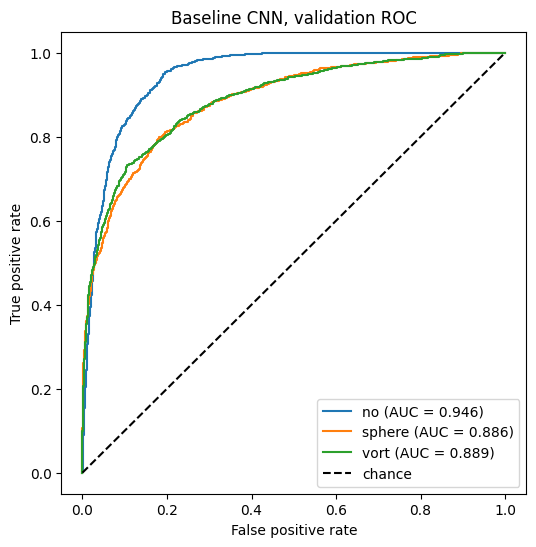

macro one-vs-rest AUC: 0.9068502399999999


In [11]:
probs, ys = predict(model, val_loader)

plt.figure(figsize=(6, 6))
for k, name in enumerate(CLASSES):
    # one-vs-rest: this class against the other two
    fpr, tpr, _ = roc_curve(ys == k, probs[:, k])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Baseline CNN, validation ROC")
plt.legend()
plt.show()

print("macro one-vs-rest AUC:", roc_auc_score(ys, probs, multi_class="ovr"))

## 7. Improvements

Each experiment trains a fresh model for the same number of epochs and reports the **last** epoch on the validation split. Validation is also what I compare experiments with, so the best number is slightly optimistic (there is no separate test set in this task).

| # | change | what it tests |
|---|---|---|
| 0 | baseline: small CNN, Adam, no augmentation | reference |
| 1 | + augmentation (mirror, 90-degree turns) | does more variety help? |
| 2 | + AdamW, cosine learning-rate schedule, weight decay (no augmentation) | does the optimizer set-up help? |
| 3 | 1 + 2 together | do they add up? |
| 4 | ResNet-18 (ImageNet weights, first layer adapted to 1 channel) + augmentation + cosine | does a bigger pretrained backbone help? |

In [12]:
def make_resnet18():
    from torchvision.models import ResNet18_Weights, resnet18

    m = resnet18(weights=None if SMOKE else ResNet18_Weights.IMAGENET1K_V1)
    w = m.conv1.weight.data.sum(dim=1, keepdim=True)   # RGB filters -> one grey channel
    m.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    m.conv1.weight.data = w
    m.fc = nn.Linear(512, 3)
    return m


trained = {"0 baseline": model}
results = {"0 baseline": baseline_result}

experiments = [
    ("1 + augmentation", SmallCNN, dict(use_augment=True)),
    ("2 + AdamW, cosine, wd", SmallCNN, dict(opt="adamw", cosine=True, weight_decay=1e-2)),
    ("3 aug + AdamW, cosine, wd", SmallCNN, dict(use_augment=True, opt="adamw", cosine=True, weight_decay=1e-2)),
    ("4 ResNet-18 + aug + cosine", make_resnet18, dict(use_augment=True, opt="adamw", cosine=True, weight_decay=1e-2, lr=5e-4)),
]
for name, build, kwargs in experiments:
    print(f"\n=== {name}")
    try:
        net = build()
    except ImportError as exc:
        print("skipped:", exc)
        continue
    results[name] = fit(net, EPOCHS, tag=f"{name[:1]} ", **kwargs)
    trained[name] = net

print(f"\n{'experiment':32s} {'val AUC':>8s} {'val acc':>8s} {'seconds':>8s}")
for name, r in results.items():
    print(f"{name:32s} {r['auc']:8.4f} {r['acc']:8.4f} {r['seconds']:8d}")
best_name = max(results, key=lambda n: results[n]["auc"])
print("\nbest by validation AUC:", best_name)


=== 1 + augmentation
1 epoch  1  train loss 1.1002  val acc 0.3333  val AUC 0.5076
1 epoch  2  train loss 1.0912  val acc 0.4144  val AUC 0.6143
1 epoch  3  train loss 1.0217  val acc 0.4853  val AUC 0.6791
1 epoch  4  train loss 0.9643  val acc 0.4125  val AUC 0.7176
1 epoch  5  train loss 0.9182  val acc 0.4219  val AUC 0.7293
1 epoch  6  train loss 0.8799  val acc 0.4027  val AUC 0.7497
1 epoch  7  train loss 0.8406  val acc 0.3656  val AUC 0.7310
1 epoch  8  train loss 0.7993  val acc 0.5325  val AUC 0.8007
1 epoch  9  train loss 0.7711  val acc 0.3944  val AUC 0.7670
1 epoch 10  train loss 0.7313  val acc 0.6275  val AUC 0.8495
1 epoch 11  train loss 0.7009  val acc 0.3877  val AUC 0.8433
1 epoch 12  train loss 0.6796  val acc 0.6091  val AUC 0.8460
1 epoch 13  train loss 0.6551  val acc 0.6928  val AUC 0.8730
1 epoch 14  train loss 0.6330  val acc 0.7325  val AUC 0.8898
1 epoch 15  train loss 0.6075  val acc 0.4795  val AUC 0.8766

=== 2 + AdamW, cosine, wd
2 epoch  1  train los

100%|██████████| 44.7M/44.7M [00:00<00:00, 191MB/s]


4 epoch  1  train loss 0.8793  val acc 0.7533  val AUC 0.9039
4 epoch  2  train loss 0.4557  val acc 0.8509  val AUC 0.9603
4 epoch  3  train loss 0.3579  val acc 0.8579  val AUC 0.9645
4 epoch  4  train loss 0.3143  val acc 0.8523  val AUC 0.9664
4 epoch  5  train loss 0.2794  val acc 0.9051  val AUC 0.9803
4 epoch  6  train loss 0.2521  val acc 0.8840  val AUC 0.9738
4 epoch  7  train loss 0.2303  val acc 0.8939  val AUC 0.9831
4 epoch  8  train loss 0.2092  val acc 0.9221  val AUC 0.9850
4 epoch  9  train loss 0.1888  val acc 0.9224  val AUC 0.9863
4 epoch 10  train loss 0.1661  val acc 0.9323  val AUC 0.9888
4 epoch 11  train loss 0.1512  val acc 0.9333  val AUC 0.9915
4 epoch 12  train loss 0.1351  val acc 0.9397  val AUC 0.9922
4 epoch 13  train loss 0.1223  val acc 0.9469  val AUC 0.9933
4 epoch 14  train loss 0.1147  val acc 0.9488  val AUC 0.9937
4 epoch 15  train loss 0.1074  val acc 0.9507  val AUC 0.9937

experiment                        val AUC  val acc  seconds
0 baselin

### Final evaluation of the best model

One-vs-rest ROC per class, the macro-average AUC the test asks for, and the confusion matrix (which classes get mixed up).

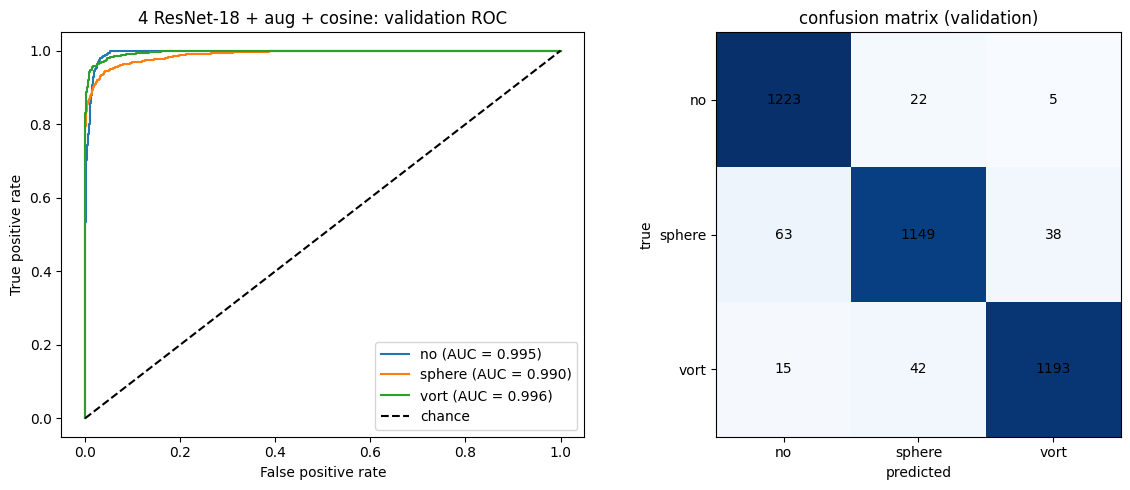

macro one-vs-rest AUC: 0.9936725333333335


In [13]:
best_model = trained[best_name]
probs, ys = predict(best_model, val_loader)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for k, name in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(ys == k, probs[:, k])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"{best_name}: validation ROC")
axes[0].legend()

cm = confusion_matrix(ys, probs.argmax(1))
axes[1].imshow(cm, cmap="Blues")
axes[1].set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES,
            xlabel="predicted", ylabel="true", title="confusion matrix (validation)")
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

print("macro one-vs-rest AUC:", roc_auc_score(ys, probs, multi_class="ovr"))

## 8. Strategy discussion

*Write this yourself after the run, from the numbers in the table above. Questions to answer:*

1. **Data:** why re-split 90:10 and stratify, and what could go wrong if the validation images leaked into training?
2. **Baseline:** what did the small CNN reach, and which class was hardest to separate (see the confusion matrix)? Any physical reason?
3. **Experiments:** which change helped most, which did nothing or hurt, and why do you think so? (augmentation assumption: rotations and mirrors keep the class, is that true for these simulations?)
4. **Honesty about the numbers:** the comparison used the validation split, so the best AUC is slightly optimistic. What would you do with a separate test set or more time (several seeds, error bars, cross-validation)?
5. **Next steps:** what would you try with more compute?

## 9. Save

Weights go to `weights/` (`/content/weights` on Colab) together with the results table. On Colab the files vanish when the runtime ends, so download them (cell below) and put the notebook with its outputs into your repository.

In [14]:
WEIGHTS_DIR = Path(os.environ.get("DEEPLENSE_WEIGHTS") or ("/content/weights" if IN_COLAB else "weights"))
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

torch.save(best_model.state_dict(), WEIGHTS_DIR / "common_test_1_best.pt")
(WEIGHTS_DIR / "common_test_1_results.json").write_text(
    json.dumps({"best": best_name, "epochs": EPOCHS, "results": results, "seed": SEED}, indent=2)
)
print("saved:", sorted(p.name for p in WEIGHTS_DIR.iterdir()))

# On Colab, uncomment to download both files to your computer:
# from google.colab import files
# files.download(str(WEIGHTS_DIR / "common_test_1_best.pt"))
# files.download(str(WEIGHTS_DIR / "common_test_1_results.json"))

saved: ['common_test_1_best.pt', 'common_test_1_results.json']
